# Data Warehousing and Mining (DWM) — Experiment 07
## Experiment Title: K-Means Clustering for Stock Asset Segmentation
**Dataset:** `stock_market_data.csv` (3 Years of Daily NSE Trading Data across 20 Major Indian Stocks)

### 1. Objectives & Problem Formulation
- **Objective:** Perform unsupervised **asset risk-reward profiling and market segmentation** using the **K-Means Clustering** algorithm on the stock market dataset, determine the optimal number of clusters via the **Elbow Method (WCSS)**, and evaluate cluster cohesion and separation using the **Silhouette Score**.
- **Adaptation Note:**
  - Daily trading records ($14,800$ rows) are aggregated to the **stock entity level (`Ticker`)** across all 20 NSE stocks to construct multi-dimensional investment profiles capturing **Return** (`Avg_Daily_Return`), **Risk/Volatility** (`Annualized_Volatility`, `Avg_Intraday_Volatility`), and **Market Liquidity** (`Avg_Volume`, `Total_Traded_Volume`).

---
### 2. Library Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Set seaborn whitegrid theme
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

print("All required libraries imported successfully.")

All required libraries imported successfully.


---
### 3. Dataset Ingestion & Preprocessing
- Load `stock_market_data.csv`.
- Convert `Date` to `datetime`.
- Derive `Intraday_Volatility` as $\frac{\text{High\_Price} - \text{Low\_Price}}{\text{Open\_Price}} \times 100$.
- Verify zero missing values and inspect the dataset dimensions.

In [2]:
df = pd.read_csv('stock_market_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Intraday_Volatility'] = (((df['High_Price'] - df['Low_Price']) / df['Open_Price']) * 100).round(2)

print("Dataset Shape:", df.shape)
print("Total Null Values:", df.isnull().sum().sum())
display(df.head())

Dataset Shape: (14800, 11)
Total Null Values: 0


,Date,Ticker,Sector,Exchange,Open_Price,High_Price,Low_Price,Close_Price,Volume,Daily_Return,Intraday_Volatility
0,2023-10-12,BAJAJ-AUTO,Auto,NSE,4851.06,4914.02,4818.72,4871.67,472168,0.42,1.96
1,2023-10-12,BRITANNIA,FMCG,NSE,4391.48,4400.68,4342.60,4371.11,518582,-0.46,1.32
2,2023-10-12,HCLTECH,IT,NSE,1106.03,1109.18,1079.51,1087.15,3921609,-1.71,2.68
3,2023-10-12,HDFCBANK,Banking,NSE,735.43,743.05,733.28,742.02,22025336,0.90,1.33
4,2023-10-12,HINDUNILVR,FMCG,NSE,2413.48,2425.33,2398.55,2415.37,1625010,0.08,1.11


---
### 4. Stock-Level Feature Engineering
Group daily trading records by `Ticker` and `Sector` to construct 1 summary row per stock with 5 core financial metrics:
- `Avg_Daily_Return`: Mean of `Daily_Return` ($\%$)
- `Annualized_Volatility`: Standard deviation of `Daily_Return` $\times \sqrt{252}$ ($\%$)
- `Avg_Volume`: Mean daily trading `Volume`
- `Avg_Intraday_Volatility`: Mean of `Intraday_Volatility` ($\%$)
- `Total_Traded_Volume`: Cumulative 3-year `Volume`

In [3]:
stock_df = (
    df.groupby(['Ticker', 'Sector'], as_index=False)
    .agg(
        Avg_Daily_Return=('Daily_Return', 'mean'),
        Annualized_Volatility=('Daily_Return', lambda x: x.std() * np.sqrt(252)),
        Avg_Volume=('Volume', 'mean'),
        Avg_Intraday_Volatility=('Intraday_Volatility', 'mean'),
        Total_Traded_Volume=('Volume', 'sum')
    )
    .sort_values('Ticker')
    .reset_index(drop=True)
)

stock_df['Avg_Daily_Return'] = stock_df['Avg_Daily_Return'].round(4)
stock_df['Annualized_Volatility'] = stock_df['Annualized_Volatility'].round(2)
stock_df['Avg_Volume'] = stock_df['Avg_Volume'].round(0).astype(int)
stock_df['Avg_Intraday_Volatility'] = stock_df['Avg_Intraday_Volatility'].round(2)

print(f"Stock Summary DataFrame Shape: {stock_df.shape}")
print("\nFirst 5 Stock Profiles (stock_df.head()):")
display(stock_df.head())

print("\nSummary Statistics of Stock-Level Features:")
display(stock_df.describe().T)

Stock Summary DataFrame Shape: (20, 7)

First 5 Stock Profiles (stock_df.head()):


,Ticker,Sector,Avg_Daily_Return,Annualized_Volatility,Avg_Volume,Avg_Intraday_Volatility,Total_Traded_Volume
0,BAJAJ-AUTO,Auto,0.0130,23.09,429745,2.17,318011534
1,BRITANNIA,FMCG,-0.0438,20.52,353552,2.03,261628339
2,HCLTECH,IT,-0.0220,22.34,3107488,2.19,2299540964
3,HDFCBANK,Banking,0.0470,17.27,32451568,1.61,24014160146
4,HINDUNILVR,FMCG,-0.0687,19.00,1788382,1.80,1323402396



Summary Statistics of Stock-Level Features:


,count,mean,std,min,25%,50%,75%,max
Avg_Daily_Return,20.0,-5.208000e-02,7.258162e-02,-2.150000e-01,-9.437500e-02,-4.625000e-02,-2.025000e-03,5.500000e-02
Annualized_Volatility,20.0,2.130250e+01,3.021996e+00,1.658000e+01,1.893500e+01,2.076500e+01,2.340500e+01,2.655000e+01
Avg_Volume,20.0,1.016680e+07,8.479227e+06,3.535520e+05,2.593016e+06,1.257245e+07,1.452987e+07,3.245157e+07
Avg_Intraday_Volatility,20.0,2.027500e+00,2.637558e-01,1.610000e+00,1.837500e+00,1.990000e+00,2.205000e+00,2.470000e+00
Total_Traded_Volume,20.0,7.523435e+09,6.274628e+09,2.616283e+08,1.918832e+09,9.303614e+09,1.075210e+10,2.401416e+10


---
### 5. Handling Skewed Features & Feature Scaling
- Apply `np.log1p()` to volume features (`Avg_Volume`, `Total_Traded_Volume`) to normalize right-skewness across market capitalizations.
- Apply `StandardScaler` so all clustering features have zero mean ($\mu = 0$) and unit variance ($\sigma = 1$).

In [4]:
# Create log-transformed volume features
stock_df['Avg_Volume_Log'] = np.log1p(stock_df['Avg_Volume'])
stock_df['Total_Traded_Volume_Log'] = np.log1p(stock_df['Total_Traded_Volume'])

clustering_features = [
    'Avg_Daily_Return',
    'Annualized_Volatility',
    'Avg_Volume_Log',
    'Avg_Intraday_Volatility',
    'Total_Traded_Volume_Log'
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(stock_df[clustering_features])

print("Scaled Feature Matrix Shape:", X_scaled.shape)
scaled_preview_df = pd.DataFrame(X_scaled, columns=clustering_features, index=stock_df['Ticker']).round(3)
display(scaled_preview_df.head())

Scaled Feature Matrix Shape: (20, 5)


,Avg_Daily_Return,Annualized_Volatility,Avg_Volume_Log,Avg_Intraday_Volatility,Total_Traded_Volume_Log
Ticker,,,,,
BAJAJ-AUTO,0.920,0.607,-1.879,0.554,-1.879
BRITANNIA,0.117,-0.266,-2.022,0.010,-2.022
HCLTECH,0.425,0.352,-0.425,0.632,-0.425
HDFCBANK,1.401,-1.369,1.299,-1.624,1.299
HINDUNILVR,-0.235,-0.782,-0.831,-0.885,-0.831


---
### 6. Optimal $K$ via Elbow Method
Compute Within-Cluster Sum of Squares (**WCSS / Inertia**) for $K \in \{1, 2, \dots, 10\}$ (`random_state=42, n_init=10`) and plot the Elbow curve.

Elbow Method WCSS Table:


,K (Number of Clusters),WCSS (Inertia)
0,1,100.0000
1,2,66.1639
2,3,34.2836
3,4,27.1050
4,5,19.8170
5,6,13.6451
6,7,11.0163
7,8,8.4848
8,9,6.6964
9,10,5.2518


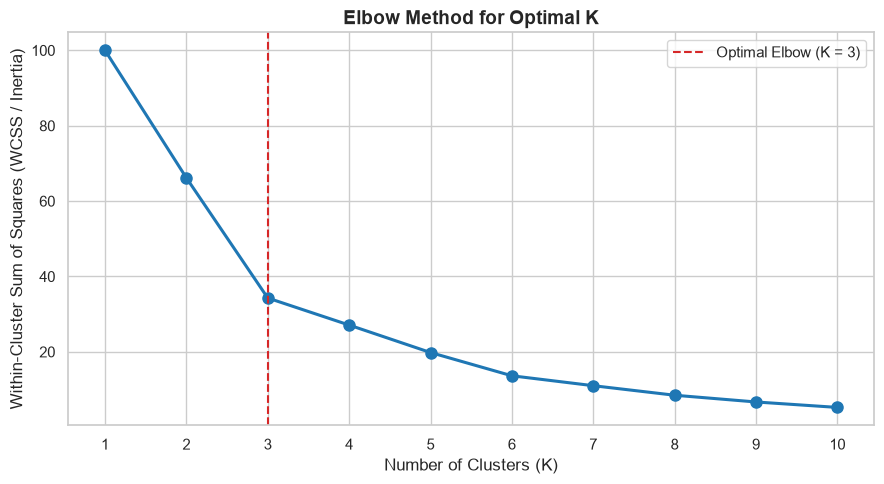

In [5]:
k_values = list(range(1, 11))
wcss_list = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss_list.append(km.inertia_)

elbow_df = pd.DataFrame({
    'K (Number of Clusters)': k_values,
    'WCSS (Inertia)': np.round(wcss_list, 4)
})
print("Elbow Method WCSS Table:")
display(elbow_df)

plt.figure(figsize=(9, 5))
plt.plot(k_values, wcss_list, marker='o', linewidth=2.2, markersize=8, color='#1f77b4')
plt.axvline(3, color='#d62728', linestyle='--', linewidth=1.5, label='Optimal Elbow (K = 3)')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS / Inertia)')
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

---
### 7. Apply K-Means Clustering ($K = 3$)
Fit `KMeans(n_clusters=3, random_state=42, n_init=10)` on the scaled feature matrix, assign `Cluster` labels (`0`, `1`, `2`) back to `stock_df`, and inspect cluster counts and memberships.

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
stock_df['Cluster'] = kmeans.fit_predict(X_scaled)

cluster_counts = stock_df['Cluster'].value_counts().sort_index()
cluster_count_df = pd.DataFrame({
    'Cluster': cluster_counts.index,
    'Stock_Count': cluster_counts.values,
    'Tickers': [
        ', '.join(stock_df[stock_df['Cluster'] == c]['Ticker'].tolist())
        for c in cluster_counts.index
    ]
})

print("Count and Membership of Stocks per Cluster:")
display(cluster_count_df)
display(stock_df[['Ticker', 'Sector', 'Avg_Daily_Return', 'Annualized_Volatility', 'Avg_Volume', 'Avg_Intraday_Volatility', 'Cluster']])

Count and Membership of Stocks per Cluster:


,Cluster,Stock_Count,Tickers
0,0,7,"HDFCBANK, ICICIBANK, INFY, ITC, KOTAKBANK, REL..."
1,1,7,"BAJAJ-AUTO, BRITANNIA, HCLTECH, HINDUNILVR, MA..."
2,2,6,"M&M, NTPC, ONGC, POWERGRID, TATAMOTORS, WIPRO"


,Ticker,Sector,Avg_Daily_Return,Annualized_Volatility,Avg_Volume,Avg_Intraday_Volatility,Cluster
0,BAJAJ-AUTO,Auto,0.0130,23.09,429745,2.17,1
1,BRITANNIA,FMCG,-0.0438,20.52,353552,2.03,1
2,HCLTECH,IT,-0.0220,22.34,3107488,2.19,1
3,HDFCBANK,Banking,0.0470,17.27,32451568,1.61,0
4,HINDUNILVR,FMCG,-0.0687,19.00,1788382,1.80,1
5,ICICIBANK,Banking,0.0550,16.58,13335637,1.67,0
6,INFY,IT,-0.0458,20.16,8570926,2.00,0
7,ITC,FMCG,-0.1503,18.30,16619542,1.69,0
8,KOTAKBANK,Banking,0.0531,17.78,21471866,1.85,0
9,M&M,Auto,0.0060,25.82,2861227,2.47,2


---
### 8. Silhouette Score Evaluation
Compute the **Silhouette Score** $s \in [-1, 1]$ for the $K = 3$ clustering solution to quantify intra-cluster cohesion vs. inter-cluster separation.

In [7]:
sil_score = silhouette_score(X_scaled, stock_df['Cluster'])
print(f"Silhouette Score for K = 3 Clustering: {sil_score:.4f}")

Silhouette Score for K = 3 Clustering: 0.4042


---
### 9. Cluster Characteristic Profiling
Group by `Cluster` to calculate mean values of `Avg_Daily_Return`, `Annualized_Volatility`, `Avg_Volume`, and `Avg_Intraday_Volatility`, and map each cluster to a clear financial persona.

In [8]:
cluster_profile = (
    stock_df.groupby('Cluster', as_index=False)
    .agg(
        Stock_Count=('Ticker', 'count'),
        Avg_Daily_Return=('Avg_Daily_Return', 'mean'),
        Annualized_Volatility=('Annualized_Volatility', 'mean'),
        Avg_Volume=('Avg_Volume', 'mean'),
        Avg_Intraday_Volatility=('Avg_Intraday_Volatility', 'mean')
    )
)
cluster_profile['Avg_Daily_Return'] = cluster_profile['Avg_Daily_Return'].round(4)
cluster_profile['Annualized_Volatility'] = cluster_profile['Annualized_Volatility'].round(2)
cluster_profile['Avg_Volume'] = cluster_profile['Avg_Volume'].round(0).astype(int)
cluster_profile['Avg_Intraday_Volatility'] = cluster_profile['Avg_Intraday_Volatility'].round(2)

# Assign business interpretation based on empirical cluster centroids
def assign_persona(row):
    if row['Annualized_Volatility'] < 19.5:
        return 'Low Volatility & High Liquidity (Blue-Chip Banking/Core Leaders)'
    elif row['Avg_Volume'] < 5000000:
        return 'Moderate Volatility & Low Share Turnover (High-Denomination FMCG/Auto/IT)'
    else:
        return 'High Volatility & High Turnover (Cyclical Auto/Energy/PSU Growth)'

cluster_profile['Market_Persona'] = cluster_profile.apply(assign_persona, axis=1)

print("Cluster Profile Summary Table:")
display(cluster_profile)

Cluster Profile Summary Table:


,Cluster,Stock_Count,Avg_Daily_Return,Annualized_Volatility,Avg_Volume,Avg_Intraday_Volatility,Market_Persona
0,0,7,-0.0180,18.62,17029306,1.78,Low Volatility & High Liquidity (Blue-Chip Ban...
1,1,7,-0.0451,20.83,1539734,2.01,Moderate Volatility & Low Share Turnover (High...
2,2,6,-0.1000,24.98,12225469,2.34,High Volatility & High Turnover (Cyclical Auto...


---
### 10. Cluster Visualizations
- **Plot 1:** Bar chart showing `Number of Stocks in Each Cluster`.
- **Plot 2:** Scatter plot of `Annualized Volatility vs Avg Daily Return` colored by `Cluster` and annotated with stock `Ticker` names.
- **Plot 3:** Scatter plot of `Avg Volume (log) vs Annualized Volatility` colored by `Cluster`.

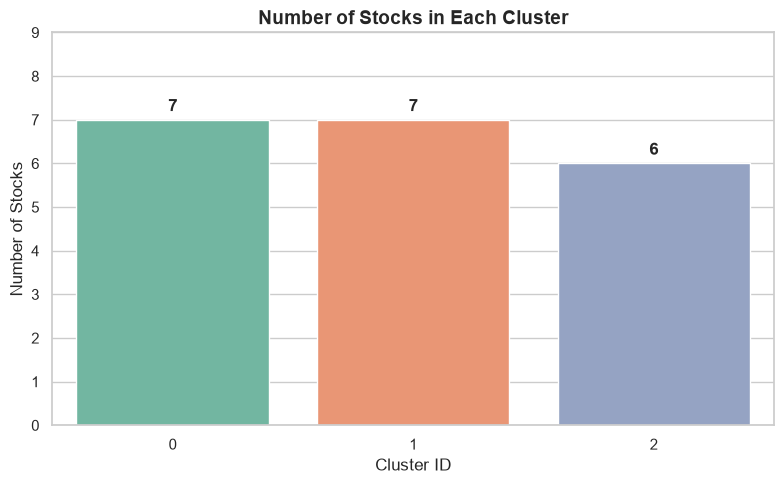

In [9]:
# Plot 1: Bar chart showing Number of Stocks in Each Cluster
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=cluster_profile,
    x='Cluster',
    y='Stock_Count',
    hue='Cluster',
    palette='Set2',
    legend=False
)
for i, v in enumerate(cluster_profile['Stock_Count']):
    ax.text(i, v + 0.2, str(v), ha='center', fontweight='bold', fontsize=12)
plt.ylim(0, max(cluster_profile['Stock_Count']) + 2)
plt.title('Number of Stocks in Each Cluster')
plt.xlabel('Cluster ID')
plt.ylabel('Number of Stocks')
plt.tight_layout()
plt.show()

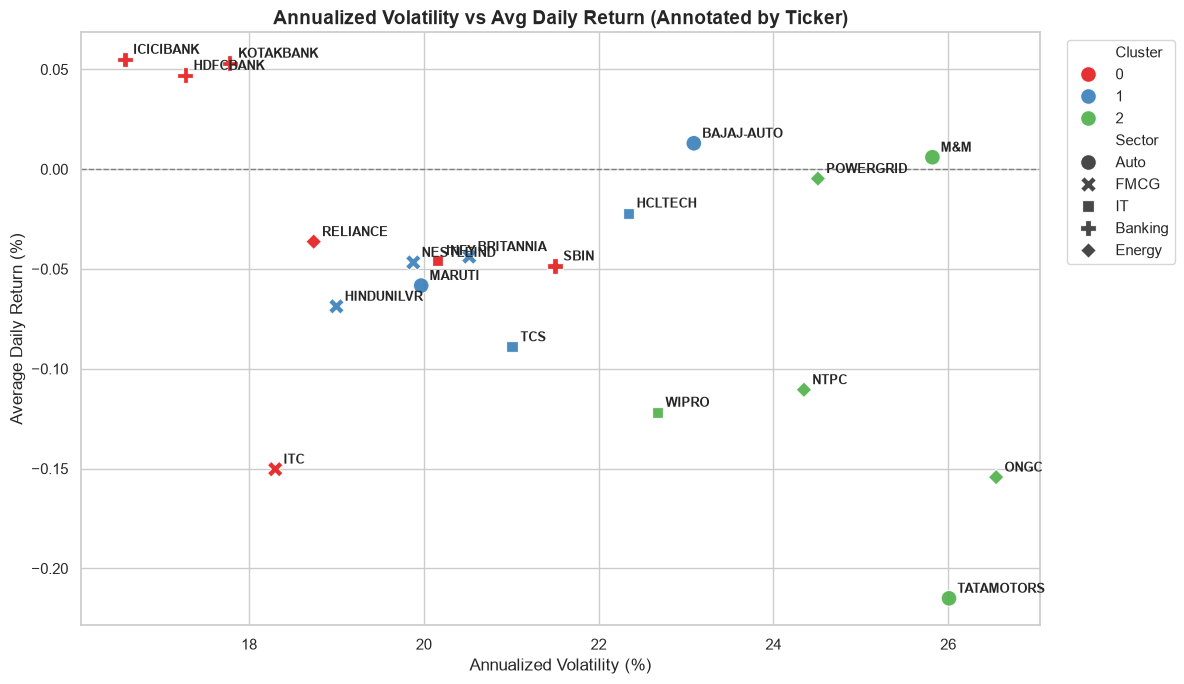

In [10]:
# Plot 2: Scatter plot Annualized Volatility vs Avg Daily Return with Ticker annotations
plt.figure(figsize=(12, 7))
palette_map = sns.color_palette('Set1', n_colors=3)

sns.scatterplot(
    data=stock_df,
    x='Annualized_Volatility',
    y='Avg_Daily_Return',
    hue='Cluster',
    style='Sector',
    palette=palette_map,
    s=130,
    alpha=0.9
)

for _, row in stock_df.iterrows():
    plt.annotate(
        row['Ticker'],
        (row['Annualized_Volatility'], row['Avg_Daily_Return']),
        xytext=(6, 4),
        textcoords='offset points',
        fontsize=9,
        fontweight='bold'
    )

plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Annualized Volatility vs Avg Daily Return (Annotated by Ticker)')
plt.xlabel('Annualized Volatility (%)')
plt.ylabel('Average Daily Return (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

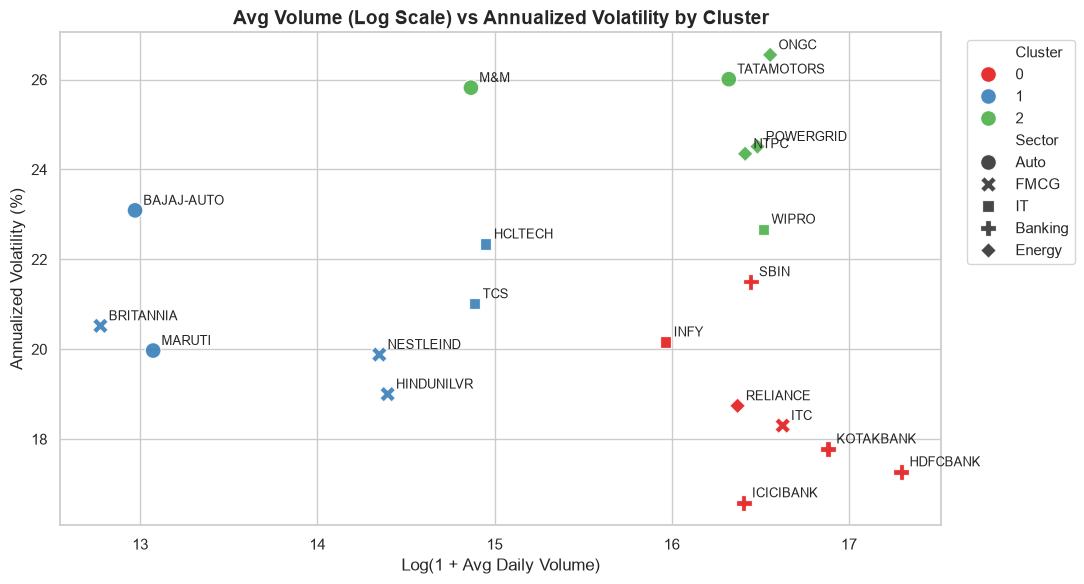

In [11]:
# Plot 3: Scatter plot Avg Volume (log) vs Annualized Volatility colored by Cluster
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=stock_df,
    x='Avg_Volume_Log',
    y='Annualized_Volatility',
    hue='Cluster',
    style='Sector',
    palette=palette_map,
    s=130,
    alpha=0.9
)

for _, row in stock_df.iterrows():
    plt.annotate(
        row['Ticker'],
        (row['Avg_Volume_Log'], row['Annualized_Volatility']),
        xytext=(6, 4),
        textcoords='offset points',
        fontsize=9
    )

plt.title('Avg Volume (Log Scale) vs Annualized Volatility by Cluster')
plt.xlabel('Log(1 + Avg Daily Volume)')
plt.ylabel('Annualized Volatility (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
### 11. Conclusion

#### Key Findings from K-Means Asset Segmentation:
1. **Optimal Cluster Selection & Cohesion:** The WCSS Elbow curve exhibits a clear inflection point at **$K = 3$** ($\text{WCSS} = 34.2836$, down from $100.00$ at $K=1$), achieving a strong positive **Silhouette Score of $0.4042$** in the 5-dimensional standardized risk-return-liquidity space.
2. **Financial Interpretation of the 3 Asset Clusters:**
   - **Cluster 0 — Low Volatility & High Liquidity (`7` Stocks: `HDFCBANK`, `ICICIBANK`, `INFY`, `ITC`, `KOTAKBANK`, `RELIANCE`, `SBIN`):** Institutional blue-chip index heavyweights with the lowest average annualized volatility ($18.62\%$), lowest intraday volatility ($1.78\%$), highest average daily volume ($17.03\text{M}$ shares), and resilient daily returns ($-0.0180\%$).
   - **Cluster 1 — Moderate Volatility & Low Share Turnover (`7` Stocks: `BAJAJ-AUTO`, `BRITANNIA`, `HCLTECH`, `HINDUNILVR`, `MARUTI`, `NESTLEIND`, `TCS`):** High per-share price defensive and quality large-caps across FMCG, Auto, and IT with moderate annualized volatility ($20.83\%$) and lower share turnover ($1.54\text{M}$ shares/day).
   - **Cluster 2 — High Volatility & High Turnover (`6` Stocks: `M&M`, `NTPC`, `ONGC`, `POWERGRID`, `TATAMOTORS`, `WIPRO`):** Cyclical Auto, Energy PSU, and high-beta stocks exhibiting the highest annualized volatility ($24.98\%$) and widest average intraday trading range ($2.34\%$).
3. **Readiness for Experiment 08:** Having partitioned the 20 NSE stocks into $K = 3$ flat clusters via K-Means, the stock-level feature profiles are ready for **Agglomerative Hierarchical Clustering & Dendrogram Analysis (Experiment 08)**.

---
### 12. Auto-export Utility
Convert `DWM_Lab_7_Stock_Market.ipynb` to `DWM_Lab_7_Stock_Market.html` using `nbconvert`.

In [12]:
import subprocess
import sys
from pathlib import Path

notebook_path = Path("DWM_Lab_7_Stock_Market.ipynb")
if notebook_path.exists():
    cmd = [
        sys.executable, "-m", "jupyter", "nbconvert",
        "--to", "html", "--no-prompt", str(notebook_path)
    ]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode == 0:
        print("Successfully exported DWM_Lab_7_Stock_Market.html")
    else:
        print("Export notice:", result.stderr)
else:
    print("Notebook file will be exported upon save.")

Successfully exported DWM_Lab_7_Stock_Market.html
